[Сайт](https://wiki.cosmos.esa.int/planck-legacy-archive/index.php/Planck_Collaboration) от коллаборации о данных и миссии

Как работают с картами Planck c точки зрения DL [github](https://github.com/rt2122/AstroDeepLearning)

Мы используем карты [y-параметра](https://ru.wikipedia.org/wiki/Эффект_Сюняева_—_Зельдовича). 
y - параметр характеризует насколько скопление исказило чернотельный спектр реликтового излучения

$$y = \int \frac{k T_e}{m c^2} n_e \sigma_t dl$$

где $n_e$ и $T_e$ - концентрация и температура электронов, $\sigma_t$ - томпсоновское рассеяние 

Данные с Planck берем [отсюда](https://zenodo.org/records/7947597)

Об алгоритме [NILC](https://wiki.cosmos.esa.int/planckpla2015/index.php/Astrophysical_component_separation), с помощью которого подготовлены данные 

Данные хранятся в формате healpy 

# Download data

In [ ]:
!wget https://zenodo.org/records/7947597/files/PR4_NILC_y_map.fits

# Import packages

In [ ]:
!pip install healpy

In [1]:
import healpy as hp, numpy as np, matplotlib.pyplot as plt

# Healpy library

Разрешение карты определяется параметром NSIDE, который, как правило, выражается степенью $2$.

In [5]:
NSIDE = 2
print("Угловое разрешение NSIDE {} примерно {:.2} deg".format(NSIDE, hp.nside2resol(NSIDE, arcmin=True) / 60))

Угловое разрешение NSIDE 2 примерно 2.9e+01 deg


Функция `hp.pixelfunc.nside2npix` выдаёт число пикселей карты `NPIX` по формуле $12\times$ `NSIDE`$^2$:

In [7]:
NPIX = hp.nside2npix(NSIDE)
NPIX, 12*NSIDE**2

(48, 48)

Доступно два способа упорядочивания пикселей: `RING` (в виде колец, начиная с северного полюса налево в сторону востока, задаётся nest = **False**) и `NESTED` (nest = **True**).

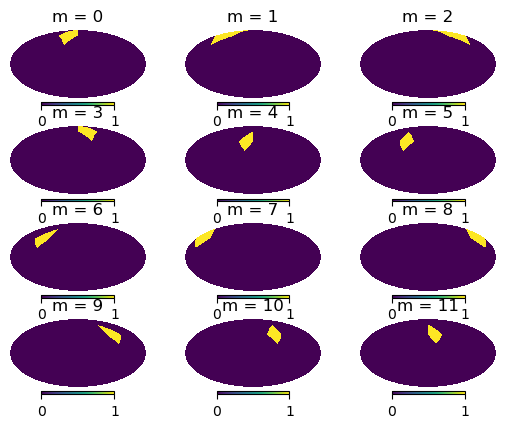

In [9]:
f, ax = plt.subplots(4, 3)

for i in range(0,12):
    m=np.zeros(NPIX)
    m[i]=1
    plt.axes(ax[i//3,i%3])
    hp.mollview(m, nest = False, title="m = {}".format(i), hold=True)

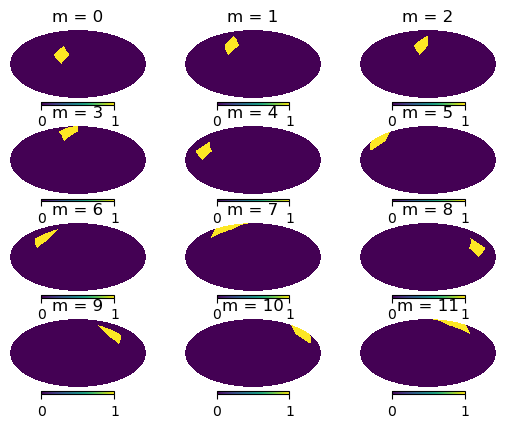

In [11]:
f, ax = plt.subplots(4, 3)

for i in range(0,12):
    m=np.zeros(NPIX)
    m[i]=1
    plt.axes(ax[i//3,i%3])
    hp.mollview(m, nest = True, title="m = {}".format(i), hold=True)

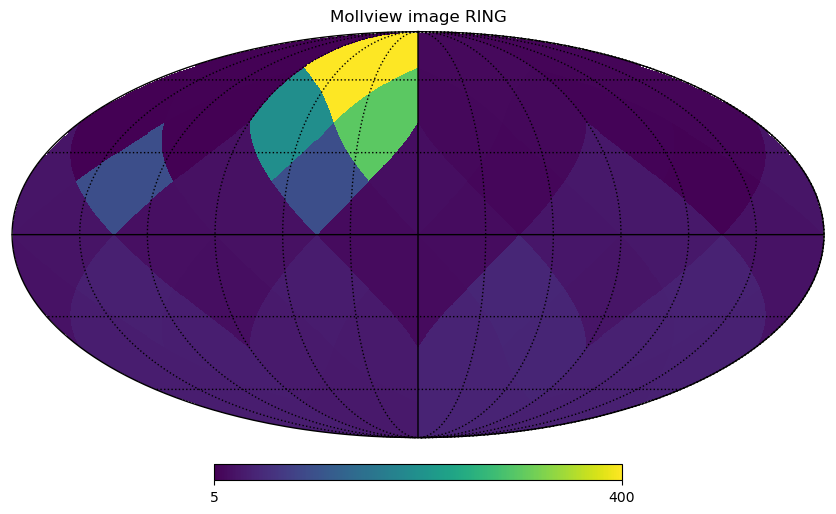

In [10]:
m = np.arange(NPIX)
m[0]=100
m[1]=200
m[2]=300
m[3]=400
m[4]=100 # лежит уже в другом "гнезде"
hp.mollview(m,nest=True, title="Mollview image RING")
hp.graticule() #turns on/off the grid

Стандартные координаты --- коширота $\theta$ (**colatitude**)  с $0$ на северном полюсе, $\pi/2$ на экваторе и $\pi$ на южном полюсе и долгота $\phi$  (**longitude**) от $0$ до $2\pi$, где $0$ в центре, обход в левую сторону.

Угловые координаты можно задавать векторами, используя функцию `hp.ang2vec`.

Так, например, направление $\theta=\frac{\pi}{2}, \phi=\frac{3\pi}{4}$ задаётся нормализованным вектором:

In [12]:
vec = hp.ang2vec(np.pi / 2, np.pi * 3 / 4)
print(vec), print(sum(vec[i]**2 for i in range(3))**0.5);

[-7.07106781e-01  7.07106781e-01  6.12323400e-17]
1.0


Также можно вызвать индексы пикселей внутри заданного углового радиуса.

Значения в этих индексах впоследствии удобно изменять.

Параметры `nest` должны быть согласованы в обоих функциях.

In [13]:
ipix_disc = hp.query_disc(nside=16, nest=False, vec=vec, radius=np.radians(25))
ipix_disc

array([ 887,  888,  950,  951,  952,  953,  954, 1013, 1014, 1015, 1016,
       1017, 1018, 1077, 1078, 1079, 1080, 1081, 1082, 1083, 1140, 1141,
       1142, 1143, 1144, 1145, 1146, 1147, 1205, 1206, 1207, 1208, 1209,
       1210, 1211, 1268, 1269, 1270, 1271, 1272, 1273, 1274, 1275, 1332,
       1333, 1334, 1335, 1336, 1337, 1338, 1339, 1340, 1396, 1397, 1398,
       1399, 1400, 1401, 1402, 1403, 1460, 1461, 1462, 1463, 1464, 1465,
       1466, 1467, 1468, 1524, 1525, 1526, 1527, 1528, 1529, 1530, 1531,
       1588, 1589, 1590, 1591, 1592, 1593, 1594, 1595, 1596, 1652, 1653,
       1654, 1655, 1656, 1657, 1658, 1659, 1716, 1717, 1718, 1719, 1720,
       1721, 1722, 1723, 1724, 1780, 1781, 1782, 1783, 1784, 1785, 1786,
       1787, 1845, 1846, 1847, 1848, 1849, 1850, 1851, 1908, 1909, 1910,
       1911, 1912, 1913, 1914, 1915, 1973, 1974, 1975, 1976, 1977, 1978,
       1979, 2037, 2038, 2039, 2040, 2041, 2042, 2102, 2103, 2104, 2105,
       2106, 2167, 2168])

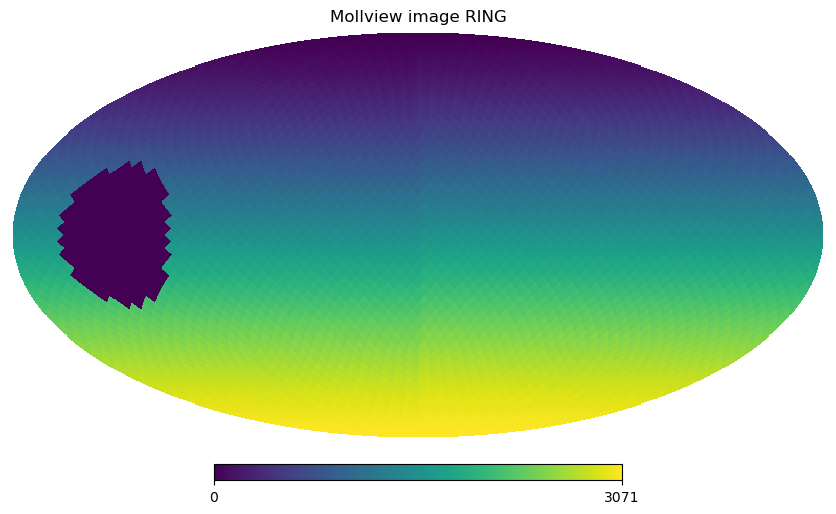

In [14]:
m = np.arange(12*16**2)
m[ipix_disc] = 0
hp.mollview(m, nest=False, title="Mollview image RING", fig=1)

Кошироту и долготу пикселя можно узнать функцией `pix2ang`.

In [15]:
theta, phi = np.degrees(hp.pix2ang(nside=32, ipix=[0, 1, 2, 3, 4]))

In [16]:
theta

array([1.46197116, 1.46197116, 1.46197116, 1.46197116, 2.92418036])

In [17]:
phi

array([ 45. , 135. , 225. , 315. ,  22.5])

По умолчанию карты конвертируются в *RING*, даже если они были упорядочены в формате *NESTED*. `nest=None` оставляет упорядочивание неизмененным.

Считывание карты команды `read_map` загружает по умолчанию первую колонку, для чтения данных из остальных колонок неоюходимо прописывать `field`.

`write_map` записывает карту в FITS формате.
Если карта представляет собой список из трёх различных карт, то они записываются в один файл как I,Q,U компоненты поляризации (параметры Стокса):


# Plot map

In [2]:
ymap = hp.read_map("PR4_NILC_y_map.fits", field=(0), h=False)

Главное свойство реликтового фона - он однороден, поэтому если мы просто нарисуем карту, то мы ничего не увидим

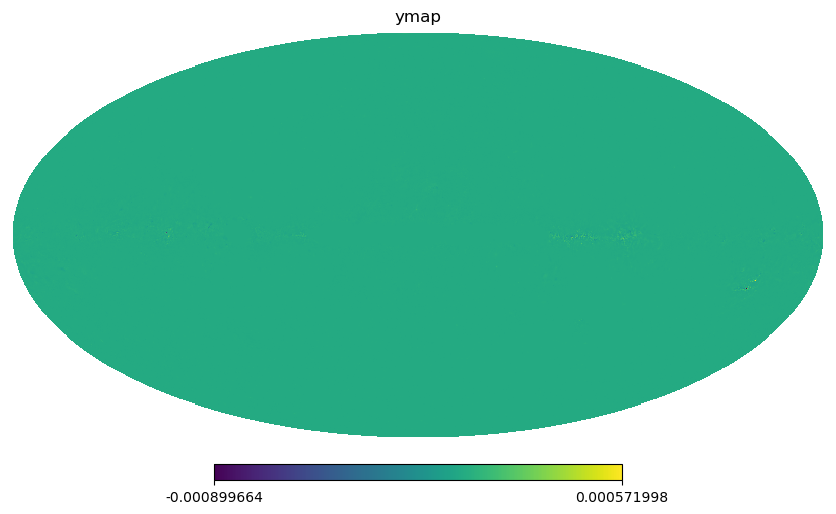

In [24]:
hp.mollview(ymap, 
            title='ymap', fig=1)

Но если обрезать по перцентилям

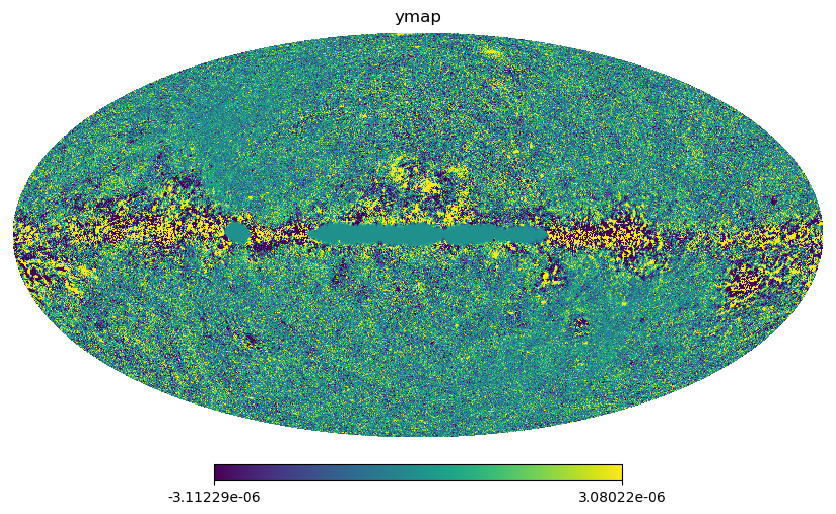

In [26]:
hp.mollview(ymap, 
            min=np.percentile(ymap, 5),    
            max=np.percentile(ymap, 95),
            title='ymap', fig=1)

Построим кусок карты в проекции - Gnomonic Projection, Galactic & Celestial

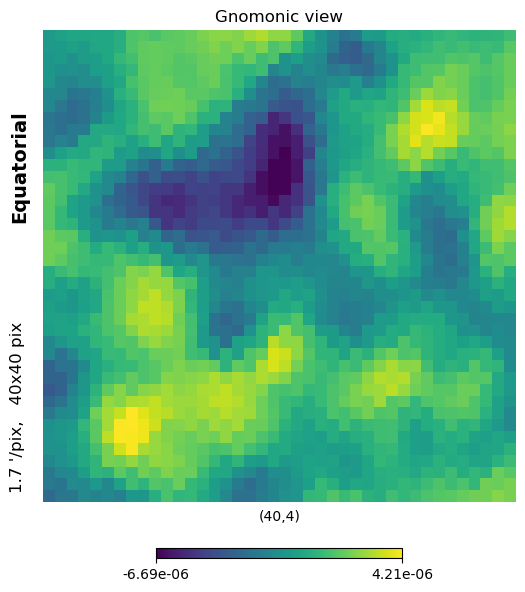

In [6]:
ra_center, dec_center = 40, 4
hp.gnomview(ymap, rot=(ra_center, dec_center), coord=('G', 'C'), xsize=40, reso=1.7,
            cmap="viridis", return_projected_map=False)
plt.show()